### 4.1. Kết nối Database & Đọc dữ liệu từ 2 SQL Views

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

# Cấu hình hiển thị biểu đồ sắc nét & tiếng Việt không lỗi font
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid")

# Kết nối PostgreSQL qua biến môi trường .env (tuyệt đối không ghi mật khẩu vào code)
load_dotenv()
engine = create_engine(os.environ["DATABASE_URL"])

# Đọc dữ liệu từ 2 SQL Views đã tạo ở Bước 3
df_orders = pd.read_sql(text("SELECT * FROM v_order_fact"), engine)
df_items = pd.read_sql(text("SELECT * FROM v_item_fact"), engine)

print(f"v_order_fact: {df_orders.shape[0]:,} dòng, {df_orders.shape[1]} cột")
print(f"v_item_fact : {df_items.shape[0]:,} dòng, {df_items.shape[1]} cột")
df_orders.head(3)

v_order_fact: 99,441 dòng, 10 cột
v_item_fact : 112,650 dòng, 6 cột


,order_id,customer_unique_id,customer_state,order_status,purchase_date,revenue,freight,delivery_days,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,delivered,2017-10-02,29.99,8.72,8.436574,0.0,4.0
1,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,delivered,2018-02-13,19.90,8.72,2.873877,0.0,5.0
2,5ff96c15d0b717ac6ad1f3d77225a350,e2dfa3127fedbbca9707b36304996dab,SP,delivered,2018-07-25,19.90,12.80,4.922396,0.0,5.0


### 4.2. Đối soát chéo (Reconciliation) SQL vs. pandas

In [2]:
# Lọc đơn hàng hợp lệ theo đúng định nghĩa đã chốt (loại bỏ canceled & unavailable)
valid_orders = df_orders[~df_orders["order_status"].isin(["canceled", "unavailable"])].copy()
valid_items = df_items[~df_items["order_status"].isin(["canceled", "unavailable"])].copy()

# 1. Đối chiếu tổng doanh thu giữa cấp đơn hàng và cấp dòng sản phẩm
rev_order_level = valid_orders["revenue"].sum()
rev_item_level = valid_items["price"].sum()

# 2. Đối chiếu các chỉ số Q3 & Q4
delivered = valid_orders[valid_orders["order_status"] == "delivered"].dropna(subset=["delivery_days"])
late_rate = delivered["is_late"].mean() * 100

cust_counts = valid_orders.groupby("customer_unique_id")["order_id"].nunique()
repeat_rate = (cust_counts >= 2).mean() * 100

print("=== BẢNG ĐỐI SOÁT SỐ LIỆU (PANDAS VALIDATION) ===")
print(f"1. Tổng đơn hợp lệ           : {len(valid_orders):,}")
print(f"2. Doanh thu (cấp đơn)       : {rev_order_level:,.2f} BRL")
print(f"3. Doanh thu (cấp sản phẩm)  : {rev_item_level:,.2f} BRL (Chênh lệch: {abs(rev_order_level - rev_item_level):.2f})")
print(f"4. Số đơn giao thành công    : {len(delivered):,} | Tỉ lệ giao trễ: {late_rate:.2f}%")
print(f"5. Tỉ lệ khách quay lại (>=2): {repeat_rate:.2f}%")

=== BẢNG ĐỐI SOÁT SỐ LIỆU (PANDAS VALIDATION) ===
1. Tổng đơn hợp lệ           : 98,207
2. Doanh thu (cấp đơn)       : 13,494,400.74 BRL
3. Doanh thu (cấp sản phẩm)  : 13,494,400.74 BRL (Chênh lệch: 0.00)
4. Số đơn giao thành công    : 96,470 | Tỉ lệ giao trễ: 8.11%
5. Tỉ lệ khách quay lại (>=2): 3.04%


### 4.3. Kiểm định thống kê cho Q3 (Mann–Whitney U & Spearman)
Dùng Mann–Whitney U thay vì t-test cho điểm review vì điểm review (1 đến 5 sao) là dữ liệu thứ bậc (ordinal) và lệch mạnh về phía 5 sao (không phân phối chuẩn). Ngoài p-value, chúng ta tính thêm CLES (Common Language Effect Size) để đo độ lớn thực tế của sự khác biệt.

In [3]:
# Lọc các đơn đã giao thành công và có cả thời gian giao lẫn điểm đánh giá
q3_df = delivered.dropna(subset=["delivery_days", "review_score"]).copy() #loại bỏ cột bị trống ở delivery_days và review_score

ontime_scores = q3_df.loc[q3_df["is_late"] == 0, "review_score"] #lọc riêng những cột đánh giá của đơn giao đúng hạn
late_scores = q3_df.loc[q3_df["is_late"] == 1, "review_score"] #lọc riêng những cột đánh giá của đơn giao trễ

# 1. Kiểm định phi tham số Mann-Whitney U (2 phía)
u_stat, p_val_mw = stats.mannwhitneyu(ontime_scores, late_scores, alternative="two-sided") #chạy kiểm định Mann-Whitney U 
#hàm trả về u_stat: thống kê U, p_val_mw: giá trị p_value

# Tính Common Language Effect Size (CLES): Xác suất 1 đơn đúng hạn có điểm cao hơn 1 đơn giao trễ
cles = u_stat / (len(ontime_scores) * len(late_scores)) # phần mẫu số là tổng số cặp so sánh có thể tạo khi ghép 1 đơn đúng hạn với 1 đơn trễ,chia u_stat cho xác suất từ 0->1

# 2. Tương quan hạng Spearman giữa số ngày giao hàng và điểm review
rho, p_val_sp = stats.spearmanr(q3_df["delivery_days"], q3_df["review_score"]) #tính giữa thời gian giao hàng thực tế và điểm đánh giá (vd: khi thời gian giao tăng lên thì điểm đánh giá có xu hướng giảm không)

print("=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ Q3 (DELIVERY VS. REVIEWS) ===")
print(f"Số mẫu hợp lệ (delivered + có review): {len(q3_df):,} đơn")
print(f"Điểm TB Đúng hạn (n={len(ontime_scores):,}): {ontime_scores.mean():.2f} | Trung vị: {ontime_scores.median():.1f}")
print(f"Điểm TB Trễ hạn  (n={len(late_scores):,}): {late_scores.mean():.2f} | Trung vị: {late_scores.median():.1f}")
print(f"Chênh lệch trung bình                : {ontime_scores.mean() - late_scores.mean():.2f} điểm")
print(f"Mann-Whitney U statistic             : {u_stat:,.0f} | p-value = {p_val_mw:.2e}")
print(f"Common Language Effect Size (CLES)   : {cles:.3f} (Xác suất đơn đúng hạn > đơn trễ: {cles*100:.1f}%)")
print(f"Spearman correlation (rho)           : {rho:.3f} | p-value = {p_val_sp:.2e}")

=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ Q3 (DELIVERY VS. REVIEWS) ===
Số mẫu hợp lệ (delivered + có review): 95,824 đơn
Điểm TB Đúng hạn (n=88,163): 4.29 | Trung vị: 5.0
Điểm TB Trễ hạn  (n=7,661): 2.57 | Trung vị: 2.0
Chênh lệch trung bình                : 1.73 điểm
Mann-Whitney U statistic             : 524,709,892 | p-value = 0.00e+00
Common Language Effect Size (CLES)   : 0.777 (Xác suất đơn đúng hạn > đơn trễ: 77.7%)
Spearman correlation (rho)           : -0.235 | p-value = 0.00e+00


### 4.4. Vẽ 5 biểu đồ kể chuyện dữ liệu (Data Storytelling Q1–Q5)

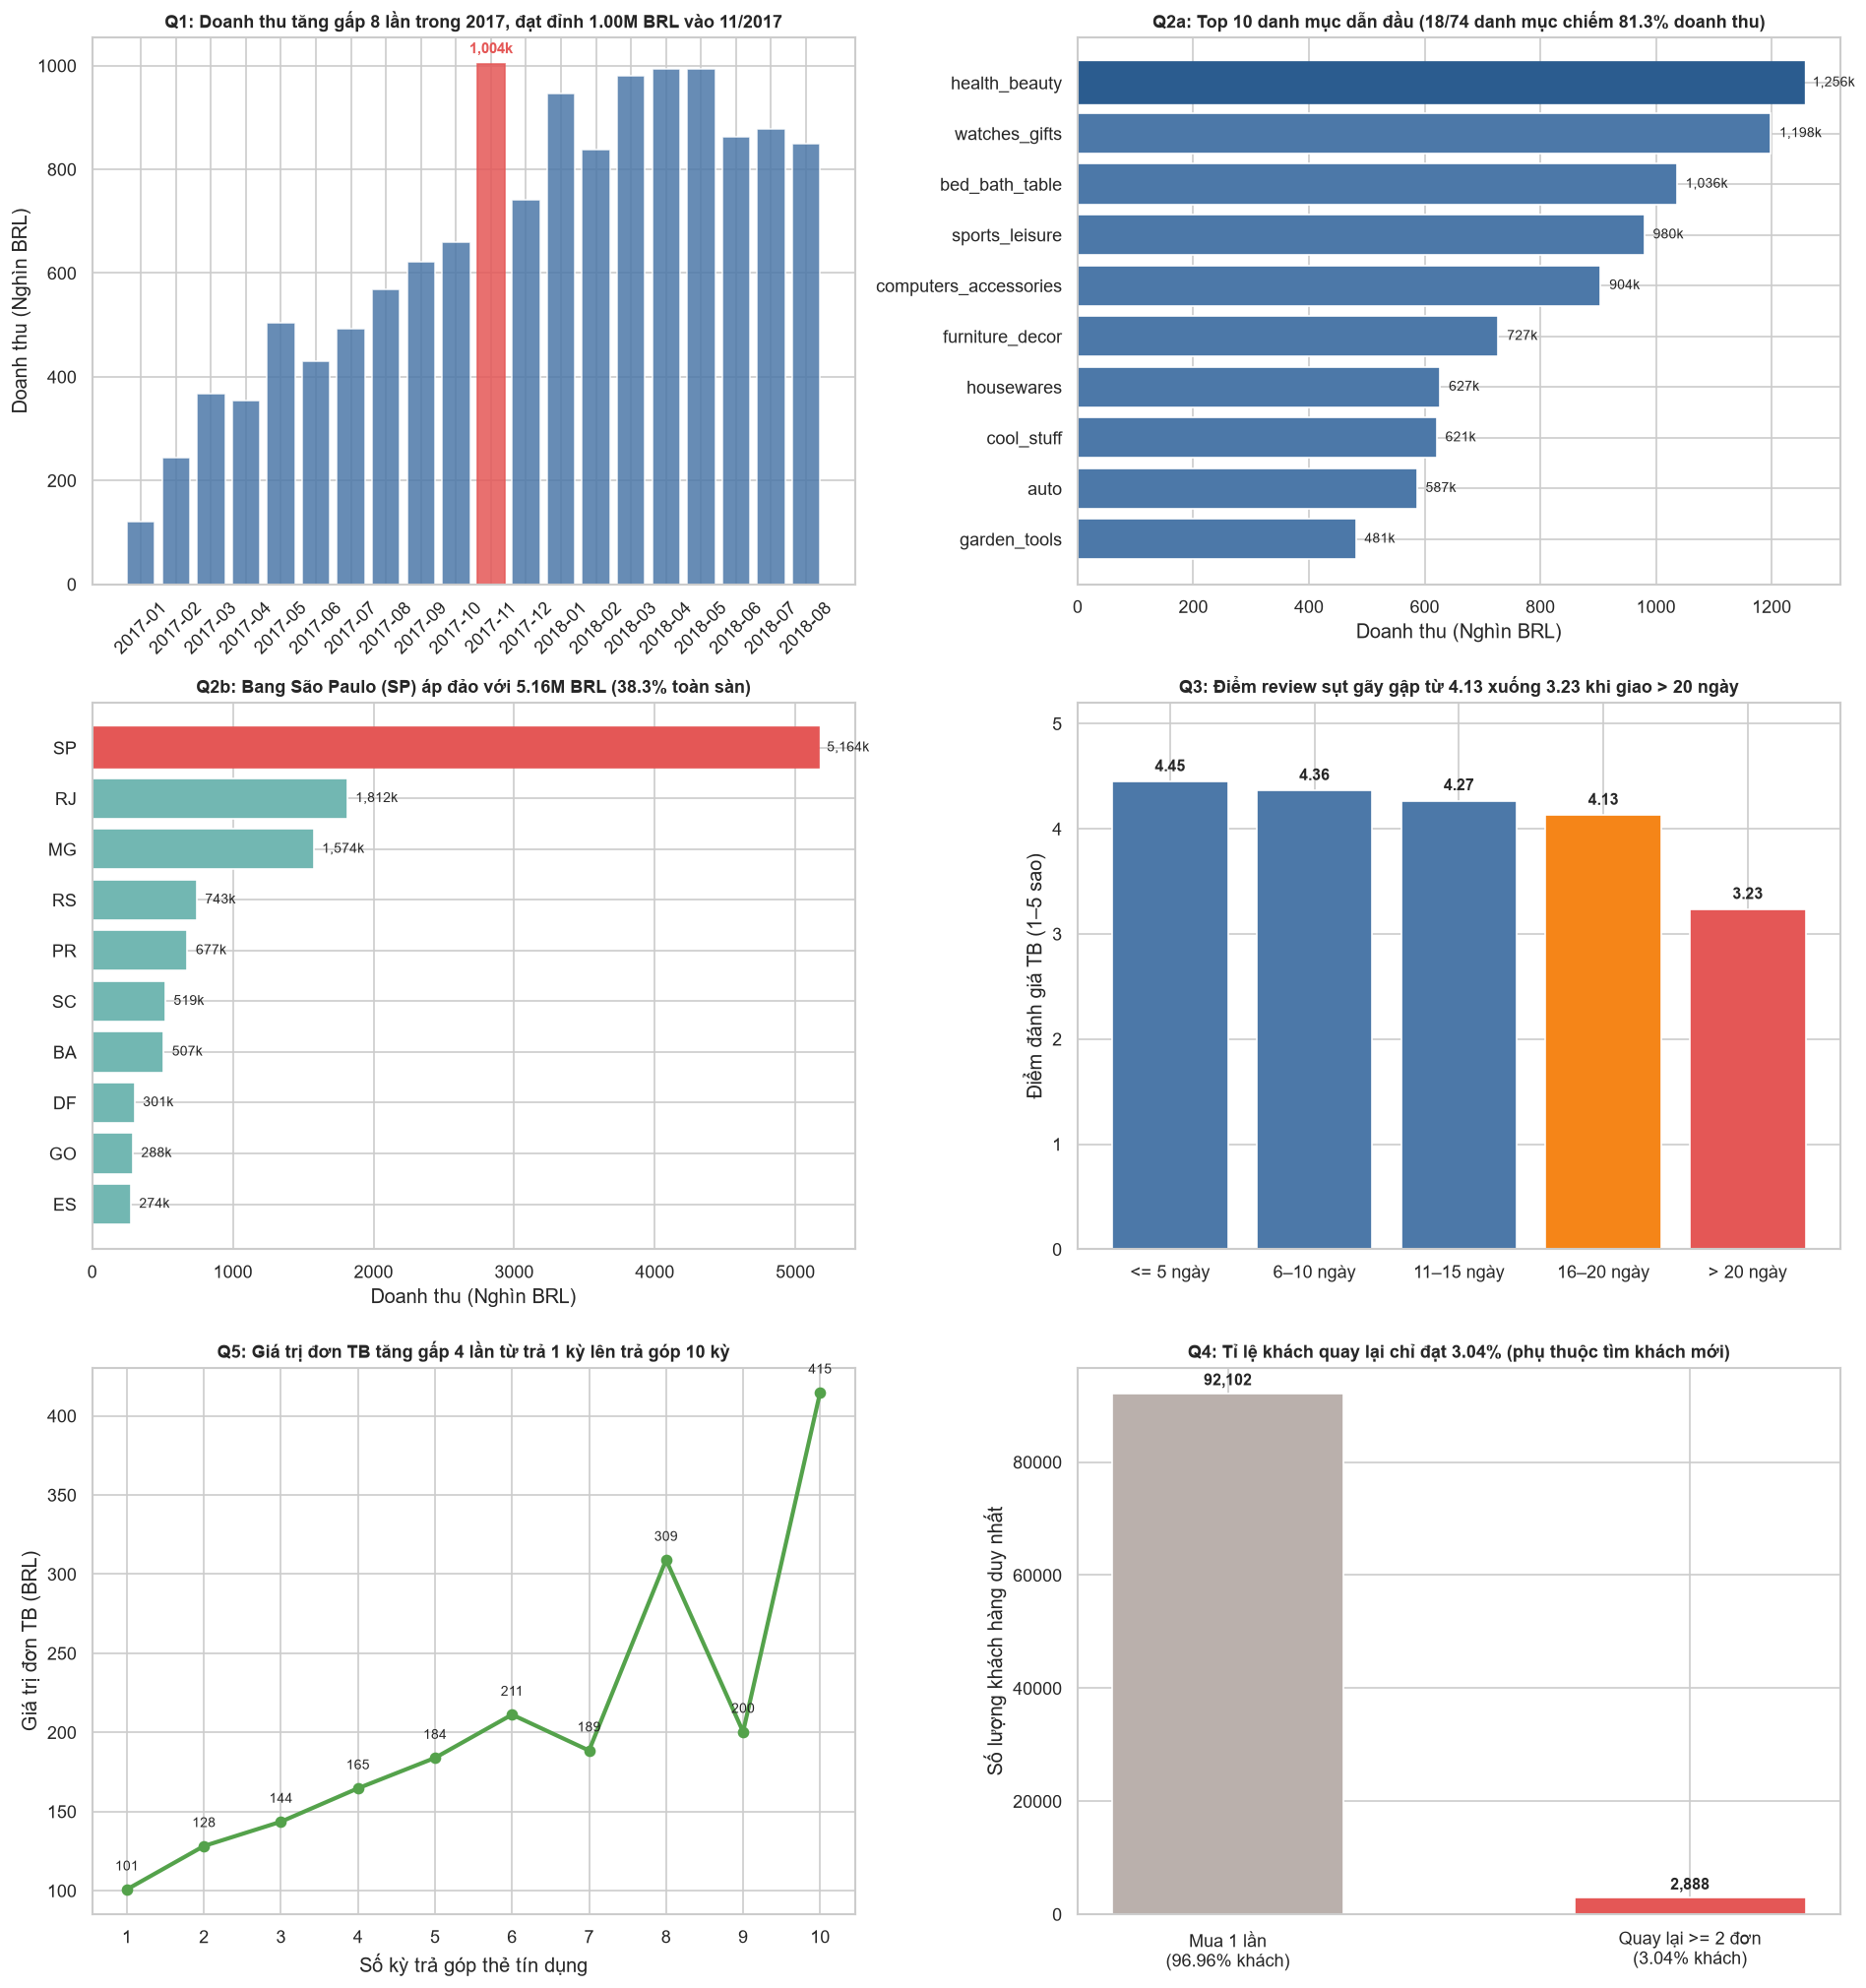

In [4]:
# Kéo thêm dữ liệu thanh toán để vẽ biểu đồ Q5
df_payments = pd.read_sql(text("""
    WITH pay_order AS (
        SELECT order_id, SUM(payment_value) AS total_paid,
               (ARRAY_AGG(payment_type ORDER BY payment_value DESC))[1] AS main_type,
               MAX(payment_installments) AS installments
        FROM olist_order_payments GROUP BY order_id
    )
    SELECT p.* FROM pay_order p
    JOIN olist_orders o USING (order_id)
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
"""), engine)

fig, axes = plt.subplots(3, 2, figsize=(16, 17)) #tạo ra một tấm bảng vẽ lớn (fig) với 3 hàng và 2 cột, lưu trong mảng 2 chiều axes (axes[2,1] là ô hàng 3 và cột 2)
plt.subplots_adjust(hspace=0.42, wspace=0.25) # mở khoảng cách chiều dọc hspace và chiều ngang wspace để các chữ trên trục của từng biểu đồ không bị chồng đè lên nhau

# --- BIỂU ĐỒ 1 (Q1): Doanh thu theo tháng (2017-01 đến 2018-08) ---
valid_orders["month"] = pd.to_datetime(valid_orders["purchase_date"]).dt.to_period("M").astype(str) #chuyển purchase_date sang Y-M-D cắt lấy Y-M, lưu vào month 
m_df = valid_orders[(valid_orders["month"] >= "2017-01") & (valid_orders["month"] <= "2018-08")] #lọc đúng 20 tháng ổn định
monthly_rev = m_df.groupby("month")["revenue"].sum() / 1e3  # gom nhóm theo tháng rồi cộng tổng doanh thu đổi sang đơn vị nghìn BRL để gọn hơn

ax1 = axes[0, 0]
bars1 = ax1.bar(monthly_rev.index, monthly_rev.values, color="#4C78A8", alpha=0.85)
# Highlight đỉnh tháng 11/2017 (Black Friday)
peak_idx = list(monthly_rev.index).index("2017-11")
bars1[peak_idx].set_color("#E45756")
ax1.set_title("Q1: Doanh thu tăng gấp 8 lần trong 2017, đạt đỉnh 1.00M BRL vào 11/2017", fontweight="bold", fontsize=11)
ax1.set_ylabel("Doanh thu (Nghìn BRL)")
ax1.tick_params(axis="x", rotation=45)
ax1.text(peak_idx, monthly_rev.iloc[peak_idx] + 20, "1,004k", ha="center", fontweight="bold", color="#E45756", fontsize=9)

# --- BIỂU ĐỒ 2 (Q2a): Top 10 danh mục sản phẩm & Tỉ trọng cộng dồn ---
cat_rev = valid_items.groupby("category")["price"].sum().sort_values(ascending=False)
top10_cat = (cat_rev.head(10) / 1e3).sort_values()

ax2 = axes[0, 1]
bars2 = ax2.barh(top10_cat.index, top10_cat.values, color="#4C78A8")
bars2[-1].set_color("#2B5C8F")
ax2.set_title("Q2a: Top 10 danh mục dẫn đầu (18/74 danh mục chiếm 81.3% doanh thu)", fontweight="bold", fontsize=11)
ax2.set_xlabel("Doanh thu (Nghìn BRL)")
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 15, bar.get_y() + bar.get_height()/2, f"{w:,.0f}k", va="center", fontsize=8.5) #f"{w:,.0f}k" gán giá trị bên phải mỗi cột

# --- BIỂU ĐỒ 3 (Q2b): Top 10 bang đóng góp doanh thu ---
state_rev = (valid_orders.groupby("customer_state")["revenue"].sum().sort_values(ascending=False).head(10) / 1e3).sort_values()

ax3 = axes[1, 0]
bars3 = ax3.barh(state_rev.index, state_rev.values, color="#72B7B2")
bars3[-1].set_color("#E45756") # tô màu cho bang đứng đầu
ax3.set_title("Q2b: Bang São Paulo (SP) áp đảo với 5.16M BRL (38.3% toàn sàn)", fontweight="bold", fontsize=11)
ax3.set_xlabel("Doanh thu (Nghìn BRL)")
for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 60, bar.get_y() + bar.get_height()/2, f"{w:,.0f}k", va="center", fontsize=8.5)

# --- BIỂU ĐỒ 4 (Q3): Điểm review giảm gãy gập khi giao hàng > 20 ngày ---
bins = [0, 5, 10, 15, 20, 999]
labels = ["<= 5 ngày", "6–10 ngày", "11–15 ngày", "16–20 ngày", "> 20 ngày"]
q3_df["bucket"] = pd.cut(q3_df["delivery_days"], bins=bins, labels=labels)
bucket_rev = q3_df.groupby("bucket", observed=False)["review_score"].mean()

ax4 = axes[1, 1]
colors4 = ["#4C78A8", "#4C78A8", "#4C78A8", "#F58518", "#E45756"]
bars4 = ax4.bar(bucket_rev.index, bucket_rev.values, color=colors4)
ax4.set_ylim(0, 5.2) # cố định trục tung từ 0 tới 5.2 (vì 5.0 là max)
ax4.set_title("Q3: Điểm review sụt gãy gập từ 4.13 xuống 3.23 khi giao > 20 ngày", fontweight="bold", fontsize=11)
ax4.set_ylabel("Điểm đánh giá TB (1–5 sao)")
for bar in bars4:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2, h + 0.1, f"{h:.2f}", ha="center", fontweight="bold", fontsize=9.5)

# --- BIỂU ĐỒ 5 (Q5): Giá trị đơn hàng tăng theo số kỳ trả góp (1–10 kỳ) ---
cc_df = df_payments[(df_payments["main_type"] == "credit_card") & (df_payments["installments"].between(1, 10))]
inst_aov = cc_df.groupby("installments")["total_paid"].mean()

ax5 = axes[2, 0]
ax5.plot(inst_aov.index, inst_aov.values, marker="o", linewidth=2.5, color="#54A24B")
ax5.set_xticks(range(1, 11)) #ép trục hoành thể hiện cả 10 con số từ 1 tới 10
ax5.set_title("Q5: Giá trị đơn TB tăng gấp 4 lần từ trả 1 kỳ lên trả góp 10 kỳ", fontweight="bold", fontsize=11)
ax5.set_xlabel("Số kỳ trả góp thẻ tín dụng")
ax5.set_ylabel("Giá trị đơn TB (BRL)")
for x, y in zip(inst_aov.index, inst_aov.values):
    ax5.text(x, y + 12, f"{y:.0f}", ha="center", fontsize=8.5)

# --- BIỂU ĐỒ 6 (Q4): Tỉ lệ khách hàng quay lại ---
ax6 = axes[2, 1]
cust_type = pd.Series({
    "Mua 1 lần\n(96.96% khách)": (cust_counts == 1).sum(),
    "Quay lại >= 2 đơn\n(3.04% khách)": (cust_counts >= 2).sum()
})
bars6 = ax6.bar(cust_type.index, cust_type.values, color=["#BAB0AC", "#E45756"], width=0.5)
ax6.set_title("Q4: Tỉ lệ khách quay lại chỉ đạt 3.04% (phụ thuộc tìm khách mới)", fontweight="bold", fontsize=11)
ax6.set_ylabel("Số lượng khách hàng duy nhất")
for bar in bars6:
    h = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2, h + 1500, f"{h:,}", ha="center", fontweight="bold", fontsize=9.5)

plt.tight_layout() # tự động căn chỉnh xung quanh để không mất nhãn chữ
plt.show()

Hạn chế của phân tích (Limitations)
1. **Cửa sổ thời gian quan sát giới hạn (2016–2018):** Dữ liệu chỉ phản ánh một lát cắt ~2 năm của thị trường TMĐT Brazil; các khách hàng mua lần đầu vào cuối kỳ (`06–08/2018`) có thể chưa kịp phát sinh đơn quay lại, khiến tỉ lệ khách quay lại (`3.04%`) bị đánh giá thấp hơn thực tế dài hạn.
2. **Phân tích mô tả, chưa kiểm soát yếu tố nhiễu:** Các kết luận (như mối liên hệ giữa giao trễ và review ở Q3, hay AOV cao ở các bang xa ở Q2) mang tính tương quan quan sát, chưa tách bạch được tác động riêng rẽ của ngành hàng, giá trị sản phẩm hay năng lực từng nhà bán hàng (`seller`).
3. **Giả định chuẩn hóa dữ liệu:** Quy tắc chọn *review mới nhất* cho 547 đơn nhiều đánh giá và chọn *hình thức thanh toán có giá trị lớn nhất* làm hình thức chủ đạo cho 2,961 đơn thanh toán kết hợp giúp loại bỏ trùng lặp nhưng làm giản lược một phần thông tin chi tiết của giao dịch.
4. **Thiếu dữ liệu chi phí & chiến dịch marketing:** Bộ dữ liệu công khai chỉ cung cấp doanh thu bán hàng (`price`) và phí vận chuyển (`freight_value`), không có giá vốn hàng bán (COGS), biên lợi nhuận hay lịch sử chương trình khuyến mãi để khẳng định nguyên nhân các đợt tăng trưởng đột biến (như tháng 11/2017).